**Combined Cycle Gas Turbine (CCGT) with a Heat Recovery Steam Generator**

In this tutorial we model a ~27 MW combined cycle power plant in IDAES and validate it stream by stream against the DWSIM model `DWSim CCGT Combined Cycle.dwxmz` (built by `build_dwsim_ccgt.py`). It is the base model of the case study notebooks `01`–`04`.

### The plant:

* **Gas turbine (Brayton cycle):** ambient air is compressed, burned with natural gas in the combustor and expanded in the gas turbine.
* **Heat recovery steam generator (HRSG):** the hot exhaust (~670 °C) raises steam in a single pressure, counter-current HRSG: **superheater** → **evaporator** → **economizer** on the gas path, with a **steam drum** between the evaporator and the superheater.
* **Steam cycle (Rankine):** the steam expands in a steam turbine to the condenser; the feed pump returns the water to the HRSG.

| | Design |
|---|---|
| Air | 40 kg/s at 15 °C, 1.01325 bar (O₂/N₂/Ar 0.21/0.78/0.01) |
| Compressor | pressure ratio 17, isentropic efficiency 86 % |
| Fuel | 0.9777 kg/s CH₄/C₂H₆/C₃H₈ 0.90/0.06/0.04 at 25 °C, complete combustion, 0.5 bar combustor pressure drop |
| Gas turbine | isentropic efficiency 89 %, outlet 1.06 bar (HRSG back pressure) |
| HRSG | feed pump to 62 bar, economizer 10 K below saturation, evaporator outlet quality 0.98, superheated steam 500 °C / 60 bar, 1 kPa gas pressure drop per section |
| Steam cycle | 8.074 kg/s feedwater, steam turbine isentropic efficiency 85 % to 0.08 bar, condenser to saturated liquid, pump efficiency 80 % |

$$\eta_{CC} = \frac{W_{GT} - W_{compressor} + W_{ST} - W_{pump}}{\dot m_{fuel}\, LHV} \qquad \text{Heat rate} = \frac{3600}{\eta_{CC}}\ \mathrm{kJ/kWh}$$

---

> **Properties**
>
> Air, fuel and flue gas use a Peng-Robinson package (`flue_gas.py`) with the DWSIM binary interaction parameters. Its enthalpies include the heats of formation, so the combustion heat release comes out of the combustor's energy balance, and the ideal gas heat capacities are fitted to CoolProp up to 2000 K (the Poling correlations stop at 1000 K, well below the 1350 °C turbine inlet). Water and steam use IAPWS-95 (DWSIM uses IAPWS-IF97, which agrees to within about 0.1 %).

> **Equation oriented vs sequential**
>
> The counter-current HRSG couples the gas and water sides: the superheater needs the drum steam, which needs the evaporator, which needs the gas leaving the superheater. DWSIM solves this with two recycle (tear) blocks on the gas path. IDAES solves all the equations together, so no recycles are needed.

> **Operating modes** (`set_mode`)
>
> * `"design"`: the DWSIM specifications; fuel and feedwater flows fixed, the HRSG areas are results.
> * `"targets"`: the fuel flow is found for a turbine inlet temperature (TIT) of 1350 °C and the feedwater flow for a 10 K pinch.
> * `"offdesign"`: the HRSG areas are frozen and the steam side floats; the compressor draws a fixed volumetric flow and the turbine's swallowing capacity sets the pressure ratio. Used by the case studies.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the CCGT

In [2]:
import pandas as pd
from ccgt import setup_ccgt_model, stream_table, hrsg_areas, ccgt_results, energy_balance

pd.set_option("display.max_columns", 40)

# Build, initialize and solve the CCGT at its design point (DWSIM specifications)
model, results = setup_ccgt_model()
print(results.solver.termination_condition)

2026-11-12 16:50:49 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:50:49 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:50:49 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:50:50 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_in[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:50:50 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_out[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:50:50 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.properties_isentropic[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


... (43 outputs left out)

2026-11-12 16:50:50 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.economizer.cold_side.heat


2026-11-12 16:50:50 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.condenser.control_volume.heat


The DOF is 0


optimal


In [3]:
stream_table(model).round(3)

,Temperature (C),Pressure (bar),Mass flow (kg/s),Vapor fraction
Air,15.000,1.013,40.000,1.000
Compressed Air,420.344,17.225,40.000,1.000
Fuel,25.000,17.225,0.978,1.000
Hot Gas,1349.162,16.725,40.978,1.000
GT Exhaust,666.365,1.060,40.978,1.000
Gas After Superheater,561.853,1.050,40.978,1.000
Gas After Evaporator,286.795,1.040,40.978,1.000
Stack Gas,105.464,1.030,40.978,1.000
Feedwater,41.009,0.080,8.074,0.000
Pumped Water,41.566,62.000,8.074,0.000


### HRSG sections

The heat duties follow from the specifications; the areas follow from the duty, the LMTD and the overall heat transfer coefficient (gas side controlled finned tubes, 50–60 W/m²K). The economizer has the smallest temperature difference and so the largest area.

In [4]:
hrsg_areas(model).round(2)

,Duty (kW),U (W/m2/K),Area (m2),UA (kW/K),LMTD (K)
Superheater,5061.02,60.0,382.60,22.96,220.47
Evaporator,12768.22,55.0,2340.72,128.74,99.18
Economizer,8003.56,50.0,4270.83,213.54,37.48


### The HRSG temperature–heat (T–Q) diagram

The **pinch** is the smallest gas to water temperature difference, at the cold end of the evaporator, where the water starts to boil. It limits how much steam the exhaust can raise: the boiling plateau cannot cross the gas line.

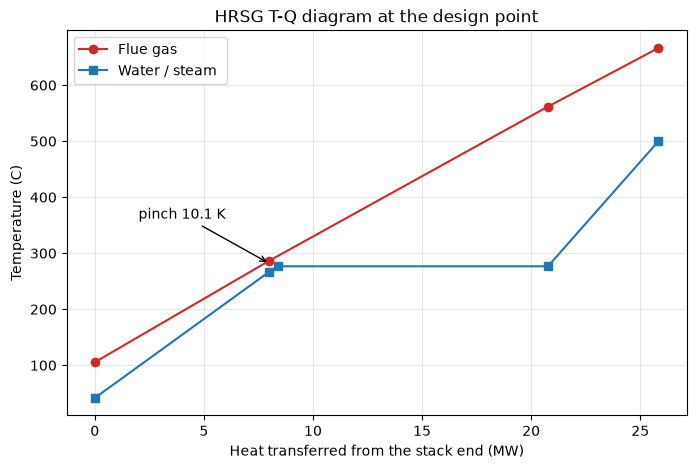

In [5]:
import matplotlib.pyplot as plt
from ccgt import plot_tq

fig, ax = plt.subplots(figsize=(8, 5))
plot_tq(ax, model)
ax.set_title("HRSG T-Q diagram at the design point")
plt.show()

### Plant performance and energy balance

In [6]:
pd.Series(ccgt_results(model)).round(3).to_frame("IDAES")

,IDAES
Fuel LHV input (kW),48298.632
Air flow (kg/s),40.000
Fuel flow (kg/s),0.978
Turbine inlet temperature (C),1349.162
GT exhaust temperature (C),666.365
Gas turbine gross (kW),35344.290
Air compressor (kW),16747.319
Gas turbine net (kW),18596.972
Steam turbine (kW),8541.760
Feed pump (kW),62.853


In [7]:
# Gas side: air + fuel + compressor work = stack + gas turbine work + HRSG duty
# Water side: feedwater + pump work + HRSG duty = condensate + blowdown + steam turbine work + condenser duty
energy_balance(model)

{'Gas side imbalance (kW)': -1.5916157281026244e-08,
 'Water side imbalance (kW)': 0.0}

## Comparison with DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file (a zip archive holding the flowsheet as XML).

In [8]:
from ccgt import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results()
streams, performance = compare_with_dwsim(model, dwsim)
performance.round(3)

,DWSIM,IDAES,Difference,Difference (%)
Fuel LHV input (kW),48297.295,48298.632,1.338,0.003
Air flow (kg/s),40.000,40.000,0.000,0.000
Fuel flow (kg/s),0.978,0.978,0.000,0.000
Turbine inlet temperature (C),1350.011,1349.162,-0.850,-0.063
GT exhaust temperature (C),666.387,666.365,-0.022,-0.003
Gas turbine gross (kW),35347.412,35344.290,-3.122,-0.009
Air compressor (kW),16742.245,16747.319,5.073,0.030
Gas turbine net (kW),18605.167,18596.972,-8.195,-0.044
Steam turbine (kW),8541.189,8541.760,0.571,0.007
Feed pump (kW),63.010,62.853,-0.157,-0.248


In [9]:
streams.pivot(index="Stream", columns="Property", values="Difference").round(3)

Property,Mass flow (kg/s),Pressure (bar),Temperature (C)
Stream,,,
Air,0.0,0.0,0.000
Blowdown,-0.0,0.0,-0.001
Compressed Air,0.0,0.0,-0.001
Condensate,0.0,0.0,-0.001
Drum Steam,0.0,0.0,-0.001
Economizer Water Out,0.0,0.0,0.000
Evaporator Outlet,0.0,0.0,-0.001
Feedwater,0.0,0.0,0.000
Fuel,0.0,0.0,0.000


The two models agree to within about 0.1 % on every turbine power, HRSG duty and efficiency. The 63 kW feed pump differs by 0.25 %, and the largest relative difference is the pinch (about 0.1 K on 10 K). The small differences come from IAPWS-95 vs IAPWS-IF97 for water and from the fitted ideal gas heat capacities. The combustor outlet differs by about 0.8 K, which is within the heat capacity fit at 1350 °C.

## Design targets mode

Instead of the DWSIM inputs, the plant is usually specified by its targets: the fuel flow gives a TIT of 1350 °C and the feedwater flow gives a 10 K pinch. In DWSIM this needed an outer secant loop around the flowsheet (`build_dwsim_ccgt.py --tune`); in IDAES it is a change of specification.

In [10]:
from ccgt import set_mode
from ccgt_case_studies import solve

set_mode(model, "targets")
solve(model)
r = ccgt_results(model)
{k: round(r[k], 3) for k in ("Fuel flow (kg/s)", "Steam flow (kg/s)", "Turbine inlet temperature (C)", "HRSG pinch (K)",
                             "Plant net power (kW)", "Combined cycle efficiency LHV (%)")}

{'Fuel flow (kg/s)': np.float64(0.979),
 'Steam flow (kg/s)': np.float64(7.928),
 'Turbine inlet temperature (C)': np.float64(1350.0),
 'HRSG pinch (K)': np.float64(10.0),
 'Plant net power (kW)': 27113.251,
 'Combined cycle efficiency LHV (%)': np.float64(56.078)}

> **About the efficiency**
>
> 56 % is high for a 27 MW plant with a single pressure HRSG; comparable real plants reach about 50–52 %. Like the DWSIM model, this one leaves out turbine blade cooling air, generator and mechanical losses, HRSG casing losses, auxiliary power and a deaerator (the feedwater enters the economizer at 42 °C). The case studies compare cases with one another, and these simplifications affect all cases alike.